In [1]:
import numpy as np
import numpy.ma as ma
from netCDF4 import Dataset
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.colors
from matplotlib.colors import ListedColormap, LinearSegmentedColormap
import matplotlib.ticker as mticker
from matplotlib import colors

import matplotlib.colors as mcolors
import iris
import cartopy
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
import cartopy.crs as ccrs

import iris.quickplot as qplt 
import iris.plot as iplt
iris.FUTURE.netcdf_promote=True

/apps/developers/compilers/canopy3/2.1.3/1/bit-64/Canopy/edm/envs/User/lib/python3.5/site-packages/matplotlib/ticker.py:1693: UserWarning: Steps argument should be a sequence of numbers
increasing from 1 to 10, inclusive. Behavior with
values outside this range is undefined, and will
raise a ValueError in future versions of mpl.
  warnings.warn('Steps argument should be a sequence of numbers\n'


In [2]:
### Upload PI
path = '/nfs/hera1/ee22kvcs/PMIP4/'
path1 = '/nfs/hera1/ee22kvcs/work/nc/xpzed/datam/pg/'
path2 = '/nfs/hera1/ee22kvcs/KCM/'

models = ['ACCESS-ESM1-5', 'HadCM3', 'IPSL-CM6A-LR', 'KCM', 'MIROC-ES2L', 'NorESM1-F', 'NorESM2-LM']
names_models_pi = ['detoc_Oyr_ACCESS-ESM1-5_piControl_r1i1p1f1_gn_1001-1100_100yr_mean_reg_360x385.nc',
                   'otracer6_xpzed_pg_5021-5120_regridded_385x360_ann_mean.nc',
                   'epc100_Omon_IPSL-CM6A-LR_piControl_r1i1p1f1_gn_375001-384912_100yr_mean_reg_360x385.nc',
                   'H0K_mm_4901_5000.codePMOSUM_100yr_mean_reg_360x385.nc',
                   'epc100_Omon_MIROC-ES2L_piControl_r1i1p1f2_gr1_225001-234912_100yr_mean_reg_360x385.nc',
                   'epc100_Omon_NorESM1-F_piControl_r1i1p1f1_gn_160101-170012_100yr_mean_reg_360x385.nc',
                   'epc100_Omon_NorESM2-LM_piControl_r1i1p1f1_gn_200101-210012_100yr_mean_reg_360x385.nc']

constraints_pi = [iris.Constraint(cube_func=lambda cube: cube.var_name == 'detoc'),
                  iris.Constraint(cube_func=lambda cube: cube.var_name == 'otracer6'),
                  iris.Constraint(cube_func=lambda cube: cube.var_name == 'epc100'),
                  iris.Constraint(cube_func=lambda cube: cube.var_name == 'var1'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'epc100'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'epc100'),
                iris.Constraint(cube_func=lambda cube: cube.var_name == 'epc100')]

PI_models = []
for i in range(np.size(models)):
    if i == 1:
        uploaded_cubes = iris.load_cube(path1+names_models_pi[i], constraints_pi[i])
    elif i == 3:
        uploaded_cubes = iris.load_cube(path2+names_models_pi[i], constraints_pi[i])
    else:
        uploaded_cubes = iris.load_cube(path+names_models_pi[i], constraints_pi[i])
    uploaded_cubes2 = iris.util.squeeze(uploaded_cubes)
    if i == 0:
        uploaded_cubes3 = uploaded_cubes2[10]
    elif i == 1:
        uploaded_cubes3 = uploaded_cubes2[7]
    else:
        uploaded_cubes3 = uploaded_cubes2
    PI_models.append(uploaded_cubes3)

/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/cf.py:798: UserWarning: Missing CF-netCDF measure variable 'areacello', referenced by netCDF variable 'detoc'
  warnings.warn(message % (variable_name, nc_var_name))
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/cf.py:798: UserWarning: Missing CF-netCDF measure variable 'volcello', referenced by netCDF variable 'detoc'
  warnings.warn(message % (variable_name, nc_var_name))
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(cf_var.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Co

In [3]:
### Upload LIG
path = '/nfs/hera1/ee22kvcs/PMIP4/'
path1 = '/nfs/hera1/ee22kvcs/work/nc/xpzec/datam/pg/'
path2 = '/nfs/hera1/ee22kvcs/KCM/'

models = ['ACCESS-ESM1-5', 'HadCM3', 'IPSL-CM6A-LR', 'KCM', 'MIROC-ES2L', 'NorESM1-F', 'NorESM2-LM']
names_models_lig = ['detoc_Oyr_ACCESS-ESM1-5_lig127k_r1i1p1f1_gn_1001-1100_100yr_mean_reg_360x385.nc',
                    'otracer6_xpzeco_pg_6651-6750_regridded_385x360_ann_mean.nc',
                    'epc100_Omon_IPSL-CM6A-LR_lig127k_r1i1p1f1_gn_230001-239912_100yr_mean_reg_360x385.nc',
                    'E7C_mm_4901_5000.codePMOSUM_100yr_mean_reg_360x385.nc',
                   'epc100_Omon_MIROC-ES2L_lig127k_r1i1p1f2_gr1_330001-339912_100yr_mean_reg_360x385.nc',
                   'epc100_Omon_NorESM1-F_lig127k_r1i1p1f1_gn_160101-170012_100yr_mean_reg_360x385.nc',
                   'epc100_Omon_NorESM2-LM_lig127k_r1i1p1f1_gn_210101-220012_100yr_mean_reg_360x385.nc']

constraints_lig = [iris.Constraint(cube_func=lambda cube: cube.var_name == 'detoc'),
                   iris.Constraint(cube_func=lambda cube: cube.var_name == 'otracer6'),
                   iris.Constraint(cube_func=lambda cube: cube.var_name == 'epc100'),
                   iris.Constraint(cube_func=lambda cube: cube.var_name == 'var1'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'epc100'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'epc100'),
                iris.Constraint(cube_func=lambda cube: cube.var_name == 'epc100')]

LIG_models = []
for i in range(np.size(models)):
    if i == 1:
        uploaded_cubes = iris.load_cube(path1+names_models_lig[i], constraints_lig[i])
    elif i == 3:
        uploaded_cubes = iris.load_cube(path2+names_models_lig[i], constraints_lig[i])
    else:
        uploaded_cubes = iris.load_cube(path+names_models_lig[i], constraints_lig[i])
    uploaded_cubes2 = iris.util.squeeze(uploaded_cubes)
    if i == 0:
        uploaded_cubes3 = uploaded_cubes2[10]
    elif i == 1:
        uploaded_cubes3 = uploaded_cubes2[7]
    else:
        uploaded_cubes3 = uploaded_cubes2
    LIG_models.append(uploaded_cubes3)

/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/cf.py:798: UserWarning: Missing CF-netCDF measure variable 'areacello', referenced by netCDF variable 'detoc'
  warnings.warn(message % (variable_name, nc_var_name))
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/cf.py:798: UserWarning: Missing CF-netCDF measure variable 'volcello', referenced by netCDF variable 'detoc'
  warnings.warn(message % (variable_name, nc_var_name))
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(cf_var.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Co

### Calculate anomalies

In [4]:
### Differences
titles = ['(a) ACCESS-ESM-1-5', '(b) HadCM3','(c) IPSL-CM6A-LR', '(d) KCM','(e) MIROC-ES2L', '(f) NorESM1-F', '(g) NorESM2-LM']
dif_expc = []
dif_perc_expc = []
for i in range (np.size(titles)):
    if i == 0:
        dif = (LIG_models[i].data-PI_models[i].data)*24*365
    elif i == 1:
        dif = (LIG_models[i].data-PI_models[i].data)*106/16 ### Redfield ratios
    else:
        dif = (LIG_models[i].data-PI_models[i].data)*60*60*24*365 ### from second to year
    ### Relative change   
    dif_perc = (LIG_models[i].data-PI_models[i].data)/PI_models[i].data*100
    
    dif_cube = PI_models[i].copy(data = dif)
    dif_perc_cube = PI_models[i].copy(data = dif_perc)
    dif_expc.append(dif_cube)
    dif_perc_expc.append(dif_perc_cube)

### MMM

In [5]:
##### MMM
### Diff
expp_pi = [cube.copy() for cube in PI_models]
expp_lig = [cube.copy() for cube in LIG_models]
expp_dif = [cube.copy() for cube in dif_expc]
perc_dif = [cube.copy() for cube in dif_perc_expc]

# Convert units
factors = [24*365,          # ACCESS-ESM-1-5
           106/16,          # HadCM3, Redfield ratios
           60*60*24*365,    # IPSL-CM6A-LR
           60*60*24*365,    # KCM
           60*60*24*365,    # MIROC-ES2L
           60*60*24*365,    # NorESM1-F
           60*60*24*365]    # NorESM2-LM

MMM_pi = sum([expp_pi[i].data * factors[i] for i in range(np.size(expp_pi))])/7
MMM_lig = sum([expp_lig[i].data * factors[i] for i in range(np.size(expp_lig))])/7

MMM_dif = sum([expp_dif[i].data for i in range(np.size(expp_dif))])/7
MMM_dif_perc = sum([perc_dif[i].data for i in range(np.size(perc_dif))])/7

# Convert arrays to iris cubes
MMM_pi_cube = expp_pi[0].copy(data = MMM_pi)
MMM_lig_cube = expp_lig[0].copy(data = MMM_lig)
MMM_dif_cube = expp_dif[0].copy(data = MMM_dif)
MMM_dif_cube2 = MMM_lig_cube-MMM_pi_cube
MMM_dif_perc_cube = perc_dif[0].copy(data = MMM_dif_perc)

In [6]:
#### Spread
sig_dif = []
for n in range(np.size(PI_models)):
    difference = expp_dif[n].data
    # Only count differences with magnitude >= 1
    # 1 corresponds to (+) differences, -1 to (-) differences, 0 to no significant differences
    signed_diff = np.where(difference >= 0.0001, 1, np.where(difference <= -0.01, -1, 0))
    sig_dif.append(signed_diff)
# Sum
sum_sig_dif = np.sum(sig_dif, axis=0)
# Consensus of at least 4 models agreeing (sum >= 4 or sum <= -4); non-consensus = |sum| < 4
consensus_values = np.where(np.abs(sum_sig_dif) >= 5, sum_sig_dif, np.nan)
consensus_cube = MMM_dif_cube.copy(data=consensus_values)

non_consensus_mask = np.abs(sum_sig_dif) < 5
non_consensus_cube = MMM_dif_cube.copy(data=non_consensus_mask.astype(float))

### Plot

Self-intersection at or near point -180 -28.738769853157986
Self-intersection at or near point -180 -32.086525640465339
Self-intersection at or near point -180 -6.7284926820751858
Self-intersection at or near point -180 -66.907454771169427
Self-intersection at or near point -180 -49.377290856342505
Self-intersection at or near point -180 -39.257055419217416
Self-intersection at or near point -180 0.76681016362696375
Self-intersection at or near point -180 78.058636722252345


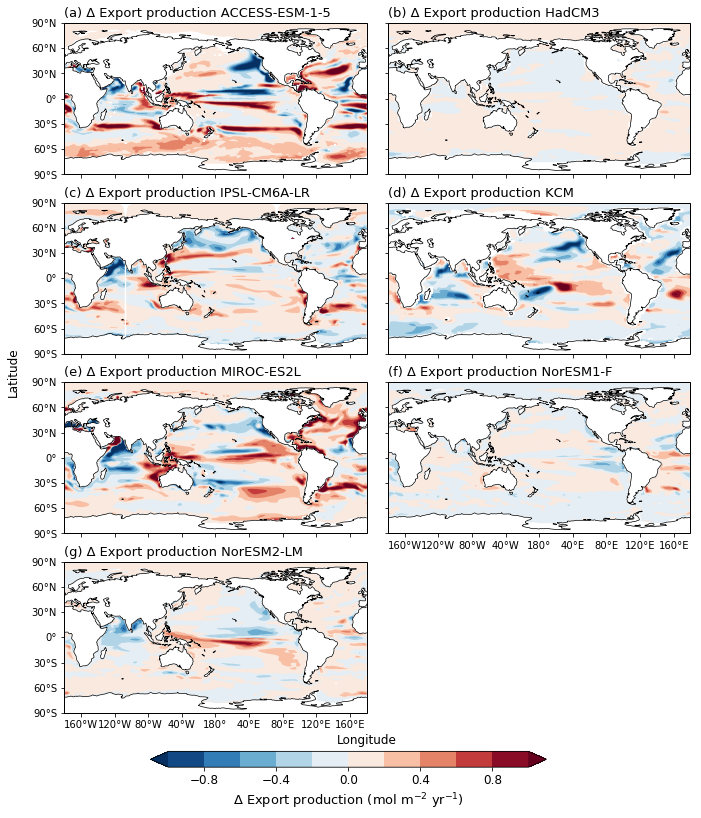

In [7]:
fig = plt.figure(figsize=(10, 11))
proj = ccrs.PlateCarree(central_longitude=180)
titles = ['ACCESS-ESM-1-5', 'HadCM3', 'IPSL-CM6A-LR', 'KCM', 'MIROC-ES2L', 'NorESM1-F', 'NorESM2-LM']
letters = ['(a)', '(b)','(c)','(d)','(e)','(f)','(g)', ]
sim = dif_expc
axes = []

for i in range(7):
    ax = fig.add_subplot(4, 2, i + 1, projection=proj)
    axes.append(ax)

for i, ax in enumerate(axes):
    ax.add_feature(cartopy.feature.COASTLINE, linewidth=0.7, edgecolor='k')
    ax.set_global()
    ax.yaxis.set_major_formatter(LATITUDE_FORMATTER)
    ax.xaxis.set_major_formatter(LONGITUDE_FORMATTER)
    ax.set_yticks(np.arange(-90, 91, 30))
    ax.tick_params(axis='y', labelsize=10)
    ax.set_xticks([-160, -120, -80, -40, 0, 40, 80, 120, 160], crs=proj)
    ax.set_xticklabels(['160°W', '120°W', '80°W', '40°W', '180°', '40°E', '80°E', '120°E', '160°E'])
    ax.tick_params(axis='x', labelsize=10)

    col = i % 2
    bottom = (i == 5) or (i == 6) # lowest panel in each column

    ax.tick_params(axis='y', labelleft=(col == 0))   # lat labels: first column only
    ax.tick_params(axis='x', labelbottom=bottom)  # lon labels: bottom panels only
 
    lev = np.arange(-1, 1+0.2, 0.2)
    ax.set_title(letters[i] + ' Δ Export production '+ titles[i] , fontsize=13, loc='left')
    im = iplt.contourf(sim[i], axes=ax, cmap='RdBu_r', levels = lev, extend='both')

# Colourbar
cbar_ax = fig.add_axes([0.2, 0.001, 0.55, 0.02]) # [left, bottom, width, height]
cbar = fig.colorbar(im, cax=cbar_ax, orientation='horizontal')
cbar.set_label('Δ Export production (mol m$^{-2}$ yr$^{-1}$)', size=13)
cbar.ax.tick_params(labelsize=12)
plt.subplots_adjust(left=0.08, right=0.95, bottom=0.06, top=0.95, wspace=0.07, hspace=0.08)
# Shared axis labels
fig.text(0.001, 0.5, 'Latitude', va='center', rotation='vertical', fontsize=12)
fig.text(0.5, 0.03, 'Longitude', ha='center', fontsize=12)

#plt.savefig('/nfs/see-fs-01_users/mlzp121/Test_HadCM3_simulations/Export_production_diff.png', bbox_inches = 'tight', dpi=300, format='png')
plt.show()

Self-intersection at or near point -180 -40.347521599817441
Self-intersection at or near point -180 -26.184146116211391
Self-intersection at or near point -180 -7.6954193251277934
Self-intersection at or near point -180 49.453125
Self-intersection at or near point -180 49.453125


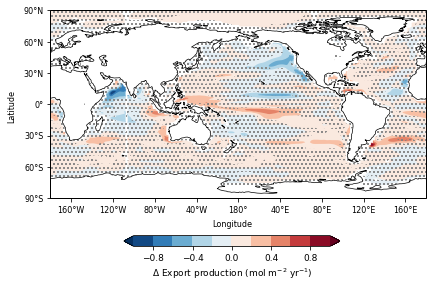

In [8]:
fig = plt.figure(figsize=(6, 5))
proj = ccrs.PlateCarree(central_longitude=180)
ax = fig.add_subplot(1, 1, 1, projection=proj)

ax.add_feature(cartopy.feature.COASTLINE, linewidth=0.7, edgecolor='k')
ax.set_global()
ax.yaxis.set_major_formatter(LATITUDE_FORMATTER)
ax.xaxis.set_major_formatter(LONGITUDE_FORMATTER)

ax.set_yticks(np.arange(-90, 91, 30))
ax.tick_params(axis='y', labelsize=8)
ax.set_xticks([-160, -120, -80, -40, 0, 40, 80, 120, 160], crs=ccrs.PlateCarree(central_longitude=180))
ax.set_xticklabels(['160°W', '120°W', '80°W', '40°W', '180°', '40°E', '80°E', '120°E', '160°E'])
ax.tick_params(axis='x', labelsize=8)
    
im = iplt.contourf(MMM_dif_cube, axes = ax, cmap = 'RdBu_r', levels = np.arange(-1, 1+0.2, 0.2), extend = 'both')
# Hatching
iplt.contourf(non_consensus_cube, levels=[0.5, 1.5], colors='none', hatches=['...'], axes=ax)
mpl.rcParams['hatch.color'] = 'gray'
cf = iplt.contourf(non_consensus_cube, levels=[0.5, 1.5], colors='none', hatches=['...'], axes=ax)

# Colourbar
cbar_ax = fig.add_axes([0.25, 0.08, 0.5, 0.03]) # [left, bottom, width, height]
cbar = fig.colorbar(im, cax=cbar_ax, orientation='horizontal')
cbar.set_label('Δ Export production (mol m$^{-2}$ yr$^{-1}$)', size=9)
cbar.ax.tick_params(labelsize=9)
plt.subplots_adjust(left=0.08, right=0.95, bottom=0.00, top=0.95, wspace=0.15, hspace=0.01)

fig.text(-0.02, 0.47, 'Latitude', va='center', rotation='vertical', fontsize=8)
fig.text(0.5, 0.135, 'Longitude', ha='center', fontsize=8)

#plt.savefig('/nfs/see-fs-01_users/mlzp121/Test_HadCM3_simulations/Export_production_mmm.png', bbox_inches='tight', dpi=300, format='png')
#plt.savefig('/nfs/see-fs-01_users/mlzp121/Test_HadCM3_simulations/Export_production_mmm_vposter.png', bbox_inches='tight', dpi=300, format='png', transparent=True)
plt.show()